# 01 · Do we want a number or a label?

**The problem.** A property file might need a missing value (the price) or
a missing label (Apartment or Villa). Which word describes each prediction?

**Why this matters.** The answer we want tells us which kind of model to
use and what a correct prediction looks like. Both examples use the
supplied property valuations.

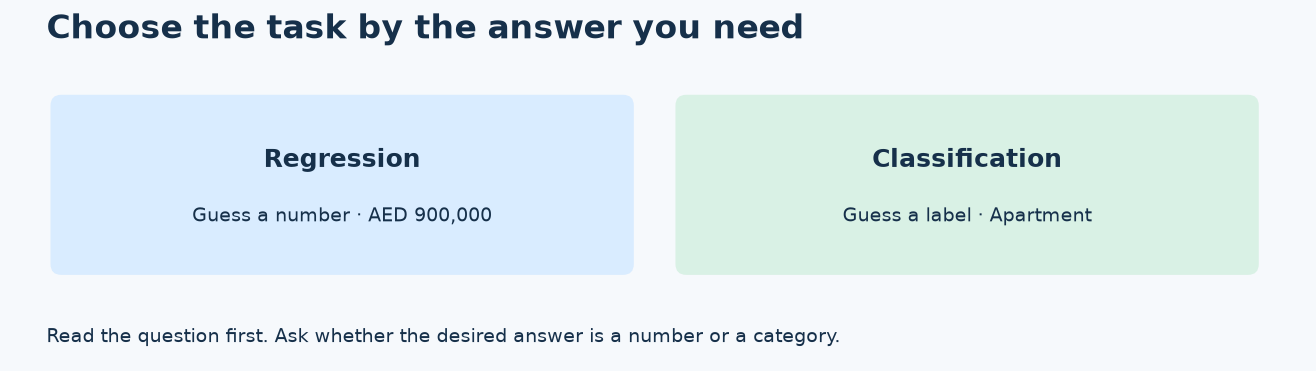

## 1 · Open the property data

**What we’re doing.** Show size, value and type for a few properties.

**Why we’re doing it.** The same file can answer different questions depending on the column we want to fill in.

**What to look for.** Value is a number. Type comes from a list of categories.

In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression

from pathlib import Path

current_folder = Path.cwd()
data_folder = next(
    (folder / "data" for folder in (current_folder, *current_folder.parents)
     if (folder / "data" / "property_valuations.csv").is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

columns = ["valuation_date", "property_type", "emirate", "size_sqft", "valuation_aed"]
properties = pd.read_csv(data_folder / "property_valuations.csv", usecols=columns, parse_dates=["valuation_date"])
dubai = properties[properties["emirate"] == "Dubai"]
dubai = dubai.query("size_sqft > 0 and valuation_aed > 0")
apartments = dubai[dubai["property_type"] == "Apartment"]

dubai[["size_sqft", "valuation_aed", "property_type"]].head(4)

,size_sqft,valuation_aed,property_type
0,1211.0,445000.0,Apartment
2,2055.0,4420000.0,Apartment
4,5693.0,5073000.0,Villa
5,798.0,388000.0,Apartment


## 2 · See a regression answer

**What we’re doing.** Fit a straight line using 12 apartment rows and guess the value for 1,200 square feet.

**Why we’re doing it.** We want an amount in AED. A regression model gives a numeric prediction.

**What to look for.** Read the answer in AED. This cell shows the form of the answer.

In [2]:
examples = apartments.sample(12, random_state=42)
line = LinearRegression().fit(examples[["size_sqft"]], examples["valuation_aed"])
new_size = pd.DataFrame({"size_sqft": [1200]})
print(f"Estimated value: AED {line.predict(new_size)[0]:,.0f}")

Estimated value: AED 1,570,587


## 3 · See a classification answer

**What we’re doing.** Use a hand-written size rule to guess a property type for two sizes.

**Why we’re doing it.** A simple rule makes the kind of answer visible before we try a model that learns from examples.

**What to look for.** Each answer is a word from the allowed list. The rule is for illustration. Property sizes can overlap.

In [3]:
size = 1200
type_guess = "Villa" if size >= 2200 else "Apartment"
print(size, "sq ft →", type_guess)

size = 3200
type_guess = "Villa" if size >= 2200 else "Apartment"
print(size, "sq ft →", type_guess)

1200 sq ft → Apartment
3200 sq ft → Villa


**Check the difference.** For a price guess, ask how far away the number
is. For a type guess, ask whether the label matches the recorded type.

**Try it.** What kind of prediction would you use for the next day’s
ATM withdrawals? What would you use to guess a document’s category?

Next, open [02 · KNN and SVM](02_KNN_and_SVM_Classifiers.ipynb) to see two
ways of learning a classification rule.